Линейная регрессия

y = ax + b
x - входы
a - множитель
b - смещение

In [121]:
src_ML_School = 'D:/MIREA/DPO/Learning/ML_School'

Генерация данных

Обычно используется skylern для стандартных методов (без градиента и т.п)


In [145]:
import numpy as np

np.random.seed(42)

x = np.random.randn(1, 100)
a, b = 2, 1
eps = .1 * np.random.randn(1, 100)
y = b + a * x + eps

x.shape, y.shape

((1, 100), (1, 100))

In [146]:
# Разбиваем данные на обучающие и тестовые
new_ind = np.arange(100) #вектор индексов от 0 до 99

np.random.shuffle(new_ind)
new_ind

array([93, 28, 55, 30, 80, 17, 54, 76, 10,  9,  2, 87, 46, 98, 84, 82, 26,
       69, 85, 52, 40, 67, 99, 63, 83,  0, 45, 11, 95, 22, 66, 20, 33, 90,
       27, 37, 97, 18, 70, 86, 77, 39, 34, 29, 72, 81, 58,  3, 92,  4, 60,
       43, 78, 96, 36, 94, 53, 74,  5, 91, 51, 48, 73, 79, 68, 21, 61, 71,
       57, 88, 50, 62, 31, 65, 14, 75, 13, 15,  7, 64, 19, 44, 35, 56,  6,
       59, 12, 23, 24, 49, 25, 41, 38, 47, 42,  8, 32, 16, 89,  1])

In [147]:
train_idx = new_ind[:70] #от 15 до 30% обычно, но всё зависит от данных
test_idx = new_ind[70:]

x_train, y_train = x[0][train_idx], y[0][train_idx]
x_test, y_test = x[0][test_idx], y[0][test_idx]


In [148]:
import matplotlib.pyplot as plt


def plot_line_or_scatter(type_plot, x_data, y_data, x_label='', y_label ='', title='', color='r', yscale_log=False):
    _, ax = plt.subplots()

    if type_plot == 'scatter':
        ax.scatter(x_data, y_data, s=10, color=color, alpha=.75)
    else:
        ax.plot(x_data, y_data, lw=2, color=color, alpha=1)

    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

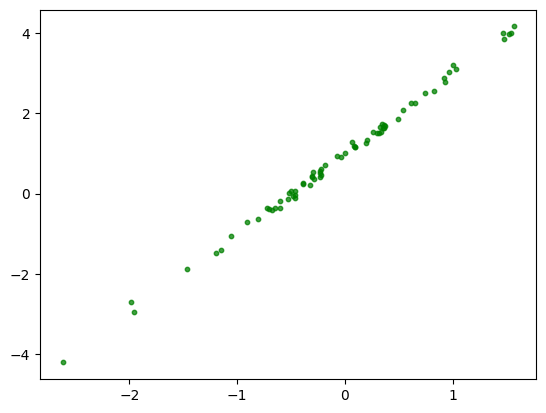

In [149]:
plot_line_or_scatter('scatter', x_train, y_train, color='green')

Обучение модели

Сами обучаем без skylern-а, определяем как и т.п.
Обновление параметров по градиентому спуску.
Ошибка по разности квадратов.

In [150]:
a = np.random.randn(1) #иницилизируем вектор в один элемент
a

array([-0.23739196])

In [151]:
b = np.random.randn(1)
b
# Для нас будем скаляром

array([1.87200568])

Определяем гиперпараметры

lr - шаг (очень важно)

In [152]:
lr = 1e-3
epochs = 100

In [153]:
Loss = []
for ep in range(epochs):
    y_pred = b + a * x_train
    error = (y_pred - y_train)
    loss = (error ** 2).mean()
    Loss.append(loss)

    b_grad = 2 * error.mean()
    a_grad = 2 * (x_train * error).mean()

    # b_grad = 1000 * error.mean()
    # a_grad = 1000 * (x_train * error).mean()

    a = a - lr * a_grad
    b = b - lr * b_grad

    if ep % 20 == 0 or ep == epochs - 1:
        print('ep: %3d loss: %.5f a: %.2f b: %.2f' % (ep, loss, a, b))

ep:   0 loss: 4.36700 a: -0.23 b: 1.87
ep:  20 loss: 4.09992 a: -0.17 b: 1.83
ep:  40 loss: 3.84986 a: -0.11 b: 1.79
ep:  60 loss: 3.61568 a: -0.06 b: 1.76
ep:  80 loss: 3.39634 a: 0.00 b: 1.72
ep:  99 loss: 3.20081 a: 0.05 b: 1.69


C:\Users\nuyki\AppData\Local\Temp\ipykernel_22316\3397267459.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('ep: %3d loss: %.5f a: %.2f b: %.2f' % (ep, loss, a, b))


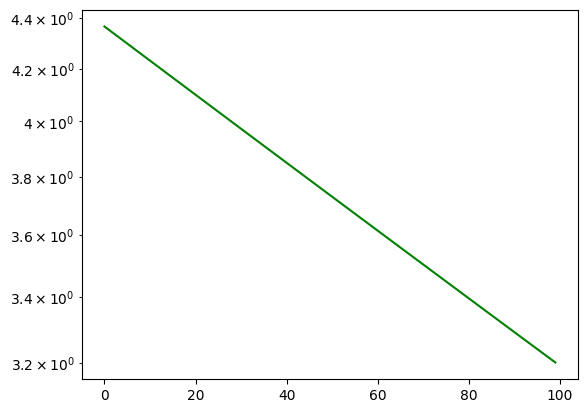

In [154]:
import matplotlib.pyplot as plt


plt.plot(np.arange(epochs), Loss, color='green')
plt.yscale('log')

In [155]:
y_test_pred = b + a * x_test

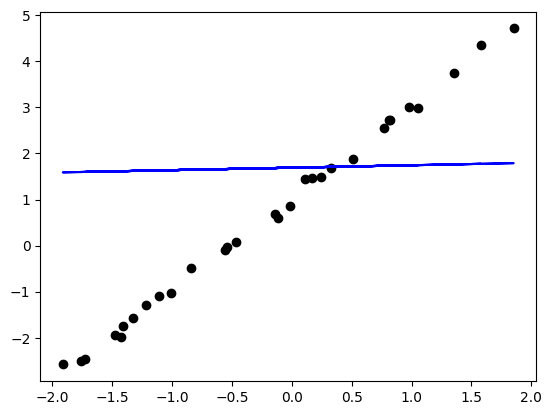

In [156]:
plt.scatter(x_test, y_test, color='black')
plt.plot(x_test, y_test_pred, color='blue')
plt.show()

Библиотека sklearn (scikit-learn)

Обучающие параметры: b=0.98595, a=1.98677


C:\Users\nuyki\AppData\Local\Temp\ipykernel_22316\2711129823.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print('Обучающие параметры: b=%.5f, a=%.5f' % (linr.intercept_, linr.coef_))


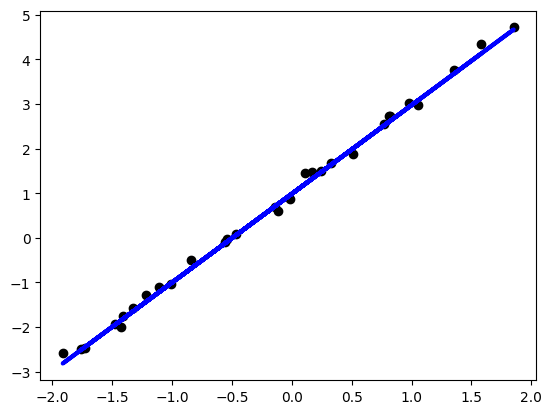

In [157]:
from sklearn.linear_model import LinearRegression


linr = LinearRegression()
linr.fit(x_train.reshape(70, 1), y_train.reshape(70, 1))
print('Обучающие параметры: b=%.5f, a=%.5f' % (linr.intercept_, linr.coef_))

y_test_pred = linr.predict(x_test.reshape(30, 1))
plt.plot(x_test, y_test_pred, color='blue', linewidth=3)
plt.scatter(x_test, y_test, color='black')
plt.show()

In [158]:
from sklearn.datasets import load_wine


data_wine = load_wine()
list(data_wine.target_names)

[np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

In [159]:
from sklearn.model_selection import train_test_split


X = data_wine.data
y = data_wine.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3)
y_test

array([0, 0, 2, 0, 2, 1, 2, 1, 1, 1, 0, 0, 2, 0, 1, 2, 0, 1, 1, 0, 1, 2,
       1, 1, 0, 0, 2, 0, 1, 0, 1, 0, 0, 2, 2, 2, 2, 2, 1, 2, 0, 2, 2, 0,
       1, 2, 0, 0, 1, 2, 1, 1, 1, 0])

In [160]:
X_train[:3]

array([[1.383e+01, 1.570e+00, 2.620e+00, 2.000e+01, 1.150e+02, 2.950e+00,
        3.400e+00, 4.000e-01, 1.720e+00, 6.600e+00, 1.130e+00, 2.570e+00,
        1.130e+03],
       [1.410e+01, 2.160e+00, 2.300e+00, 1.800e+01, 1.050e+02, 2.950e+00,
        3.320e+00, 2.200e-01, 2.380e+00, 5.750e+00, 1.250e+00, 3.170e+00,
        1.510e+03],
       [1.316e+01, 3.570e+00, 2.150e+00, 2.100e+01, 1.020e+02, 1.500e+00,
        5.500e-01, 4.300e-01, 1.300e+00, 4.000e+00, 6.000e-01, 1.680e+00,
        8.300e+02]])

In [161]:
X_train.shape

(124, 13)

In [162]:
lin_elf = LinearRegression()
lin_elf.fit(X_train, y_train)
print(f'Обучающие параметры: \nМножитель а={lin_elf.coef_}')
print(f'Смещение b={lin_elf.intercept_}')

Обучающие параметры: 
Множитель а=[-1.08457208e-01  3.89996076e-02 -1.67175869e-01  3.13347273e-02
 -4.41904488e-04  2.50423591e-01 -5.36233022e-01 -6.79235939e-01
  1.33499975e-01  6.18988521e-02 -4.70302753e-02 -2.60791691e-01
 -6.76736578e-04]
Смещение b=3.5602191926522035


Результат: 0.841080230207073


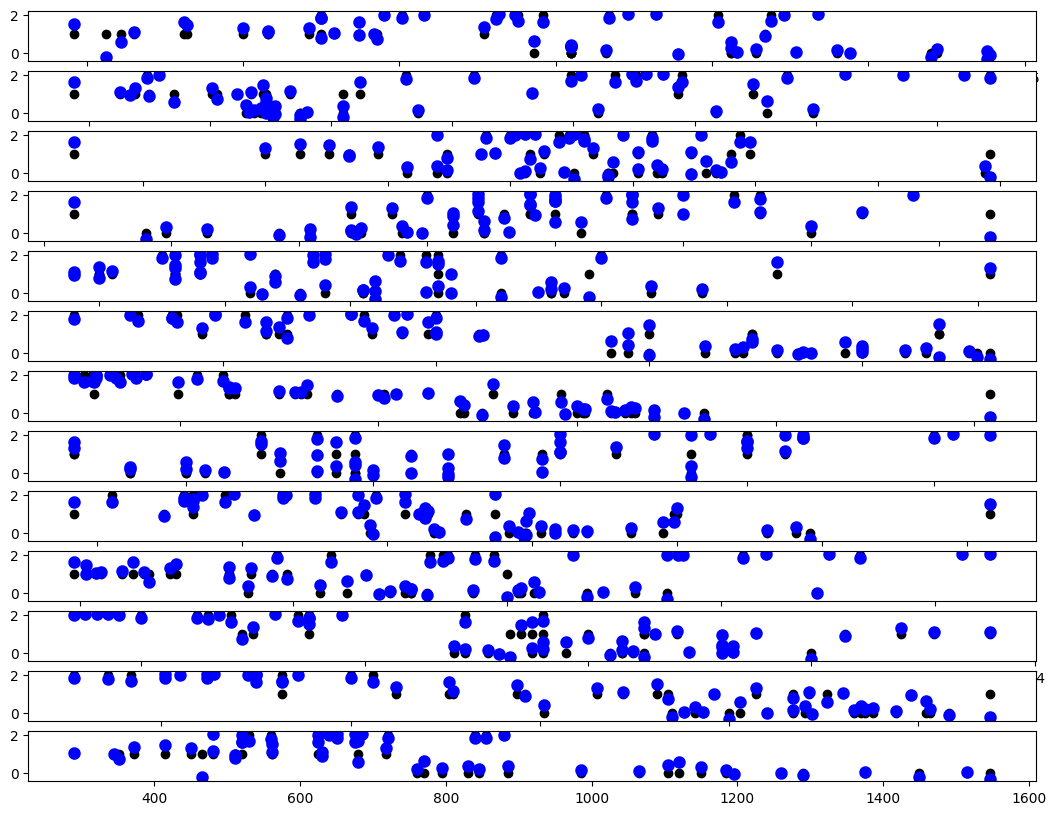

In [165]:
y_pred = lin_elf.predict(X_test)
score = lin_elf.score(X_test, y_test)
print(f'Результат: {score}')

i = 0
fig, axs = plt.subplots(nrows=13, ncols=1, figsize=(13, 10))

axs_flat = axs.flatten()

for i, ax in enumerate(axs_flat):
    ax.scatter(X_test[:, i], y_test, color='black')
    ax.scatter(X_test[:, i], y_pred, color='blue', linewidths=3)
plt.show()


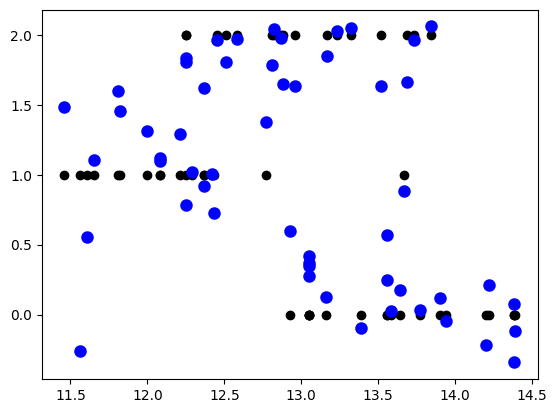

In [ ]:
plt.scatter(X_test[:, 0], y_test, color='black')
plt.scatter(X_test[:, 0], y_pred, color='blue', linewidths=3)
plt.show()

In [ ]:
y_pred_class = np.rint(y_pred)
y_pred_class[y_pred_class > 2] = 2
y_pred_class[y_pred_class < 0] = 0
y_pred_class = y_pred_class.astype('int')
score = np.sum(y_pred_class == y_test) / len(y_test)
score

np.float64(0.9074074074074074)

Логистическая регрессия

Text(0, 0.5, 'y')

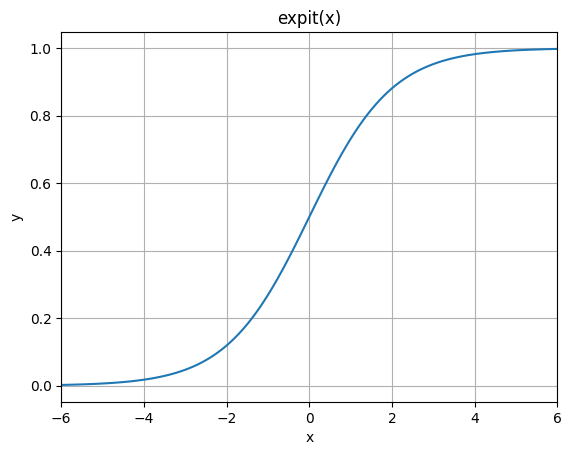

In [ ]:
from scipy.special import expit


x = np.linspace(-6, 6, 121)
y = expit(x)

plt.plot(x, y)
plt.grid()
plt.xlim(-6, 6)
plt.xlabel('x')
plt.title('expit(x)')
plt.ylabel('y')

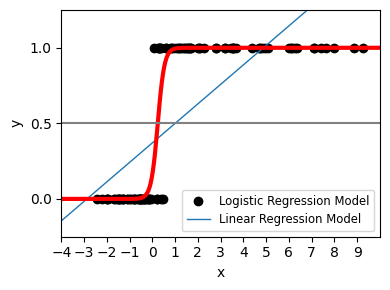

In [ ]:
from sklearn import linear_model


n_samples = 100
np.random.seed(0)
x = 1 *  np.random.normal(size=n_samples)
y = (x > 0).astype(float)
x[x > 0] *= 4
x += .3 * np.random.normal(size=n_samples)

x = x[:, np.newaxis]

log_reg = linear_model.LogisticRegression(C=1e5, max_iter=200)
log_reg.fit(x, y)

plt.figure(1, figsize=(4, 3))
plt.clf()
plt.scatter(x.ravel(), y, color='black')
# ravel - расстягивает многомерный массив в одномерный

x_test = np.linspace(-5, 10, 300)

loss = expit(x_test * log_reg.coef_ + log_reg.intercept_.ravel())
loss1 = log_reg.predict_proba(x_test[:, np.newaxis])[:, 1].ravel()
#predict_proba - вернёт вектора вероятности, а просто predict - классы

ols = LinearRegression()
ols.fit(x, y)
plt.plot(x_test, ols.coef_ * x_test + ols.intercept_, linewidth=1)
plt.plot(x_test, loss1, color='red', linewidth=3)
plt.axhline(.5, color='.5')

plt.ylabel('y')
plt.xlabel('x')
plt.xticks(range(-5, 10))
plt.yticks((0, .5, 1))
plt.ylim(-.25, 1.25)
plt.xlim(-4, 10)
plt.legend(('Logistic Regression Model', 'Linear Regression Model'), loc='lower right', fontsize='small')
plt.tight_layout()
plt.show()

Разделяющая поверхность

(-40.0, 40.0)

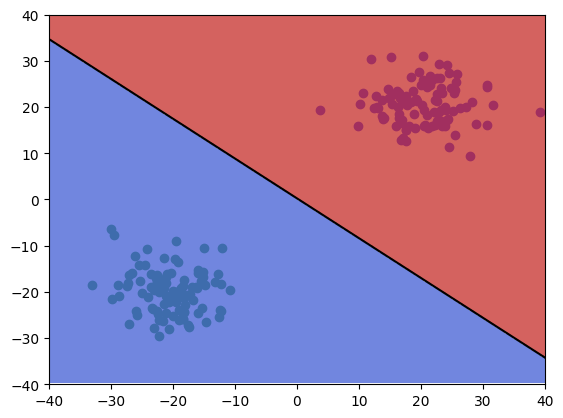

In [ ]:
np.random.seed(42)
n_samples = 100

x1 = -20 + 5 * np.random.randn(n_samples, 1)
y1 = -20 + 5 * np.random.randn(n_samples, 1)
z1 = -1 * np.ones((n_samples, 1))

x2 = 20 + 5 * np.random.randn(n_samples, 1)
y2 = 20 + 5 * np.random.randn(n_samples, 1)
z2 = np.ones((n_samples, 1))

X_train = np.hstack((np.vstack((x1, x2)), np.vstack((y1, y2))))
y = np.vstack((z1, z2))

fig, ax = plt.subplots()

ax.scatter(X_train[0: n_samples - 1, 0], X_train[0: n_samples - 1, 1], color='green')
ax.scatter(X_train[n_samples:, 0], X_train[n_samples:, 1], color='blue')

linr = linear_model.LinearRegression()
linr.fit(X_train, y)

y_pred = linr.predict(X_train)

err1 = (y_pred > 0) & (y == -1)
err2 = (y_pred < 0) & (y == 1)

err1 = err1[:, 0]
err2 = err2[:, 0]

ax.scatter(X_train[err1, 0], X_train[err1, 1], color='yellow', marker='x')
ax.scatter(X_train[err2, 0], X_train[err2, 1], color='magenta', marker='x')

h = .2
x_min, y_min = X_train.min(axis=0) - 10
x_max, y_max = X_train.max(axis=0) + 20
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
X_test = np.c_[xx.ravel(), yy.ravel()]

y_pred = linr.predict(X_test)
y_pred = y_pred.reshape(xx.shape)
y_pred[y_pred > 0] = 1
y_pred[y_pred < 0] = -1
ax.contourf(xx, yy, y_pred, cmap=plt.cm.coolwarm, alpha=.8)

xxx = np.arange(x_min, x_max, h)
yyy = -(linr.intercept_[0] + linr.coef_[0][0] * xxx) / linr.coef_[0][1]

ax.plot(xxx, yyy, color='black')
ax.set_xlim((-40, 40))
ax.set_ylim((-40, 40))


d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


(-40.0, 40.0)

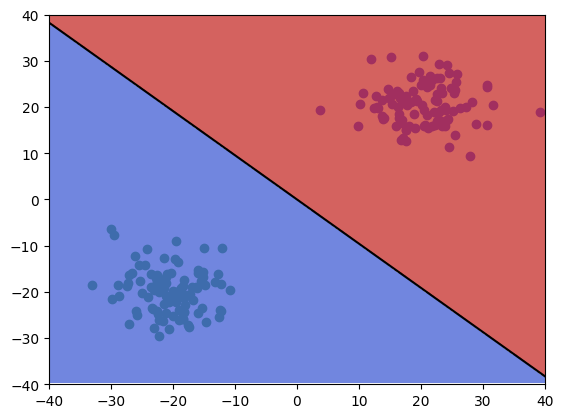

In [ ]:
np.random.seed(42)
n_samples = 100

x1 = -20 + 5 * np.random.randn(n_samples, 1)
y1 = -20 + 5 * np.random.randn(n_samples, 1)
z1 = -1 * np.ones((n_samples, 1))

x2 = 20 + 5 * np.random.randn(n_samples, 1)
y2 = 20 + 5 * np.random.randn(n_samples, 1)
z2 = np.ones((n_samples, 1))

X_train = np.hstack((np.vstack((x1, x2)), np.vstack((y1, y2))))
y = np.vstack((z1, z2))

fig, ax = plt.subplots()

ax.scatter(X_train[0: n_samples - 1, 0], X_train[0: n_samples - 1, 1], color='green')
ax.scatter(X_train[n_samples:, 0], X_train[n_samples:, 1], color='blue')

logr = linear_model.LogisticRegression()
logr.fit(X_train, y)

y_pred = logr.predict(X_train)

err1 = (y_pred == 1) & (y == 0)
err2 = (y_pred == 0) & (y == 1)

err1 = err1[:, 0]
err2 = err2[:, 0]

ax.scatter(X_train[err1, 0], X_train[err1, 1], color='yellow', marker='x')
ax.scatter(X_train[err2, 0], X_train[err2, 1], color='magenta', marker='x')

h = .2
x_min, y_min = X_train.min(axis=0) - 10
x_max, y_max = X_train.max(axis=0) + 20
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
X_test = np.c_[xx.ravel(), yy.ravel()]

y_pred = logr.predict(X_test)
y_pred = y_pred.reshape(xx.shape)
y_pred[y_pred > 0] = 1
y_pred[y_pred < 0] = -1
ax.contourf(xx, yy, y_pred, cmap=plt.cm.coolwarm, alpha=.8)

xxx = np.arange(x_min, x_max, h)
yyy = -(logr.intercept_[0] + logr.coef_[0][0] * xxx) / logr.coef_[0][1]

ax.plot(xxx, yyy, color='black')
ax.set_xlim((-40, 40))
ax.set_ylim((-40, 40))

In [ ]:
log_reg = linear_model.LogisticRegression()

data_wine = load_wine()

X = data_wine.data
y = data_wine.target

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3)

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9259259259259259


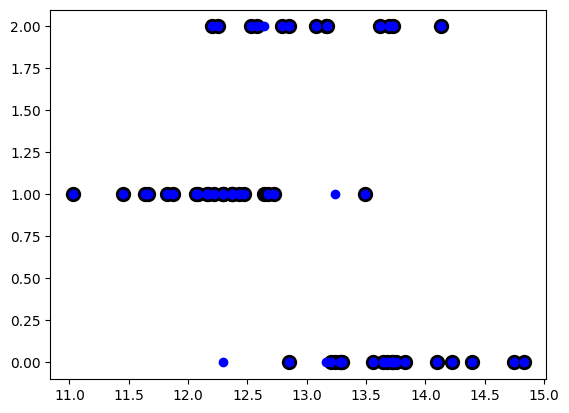

In [ ]:
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
score = log_reg.score(X_test, y_test)
print(score)
i = 0
plt.scatter(X_test[:, i], y_test, color='black', linewidths=5)
plt.scatter(X_test[:, i], y_pred, color='blue')

Деревья решений


Метрики:
sklearn - неопределенность (gini) 
Русская литература - энтропия

Стремимся к однородности ветвей

[Text(0.5, 0.9166666666666666, 'x[2] <= 2.45\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]'),
 Text(0.4230769230769231, 0.75, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]'),
 Text(0.46153846153846156, 0.8333333333333333, 'True  '),
 Text(0.5769230769230769, 0.75, 'x[3] <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]'),
 Text(0.5384615384615384, 0.8333333333333333, '  False'),
 Text(0.3076923076923077, 0.5833333333333334, 'x[2] <= 4.95\ngini = 0.168\nsamples = 54\nvalue = [0, 49, 5]'),
 Text(0.15384615384615385, 0.4166666666666667, 'x[3] <= 1.65\ngini = 0.041\nsamples = 48\nvalue = [0, 47, 1]'),
 Text(0.07692307692307693, 0.25, 'gini = 0.0\nsamples = 47\nvalue = [0, 47, 0]'),
 Text(0.23076923076923078, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]'),
 Text(0.46153846153846156, 0.4166666666666667, 'x[3] <= 1.55\ngini = 0.444\nsamples = 6\nvalue = [0, 2, 4]'),
 Text(0.38461538461538464, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [0, 0, 3]'),
 Text(0.5384615384615384, 0.25, 

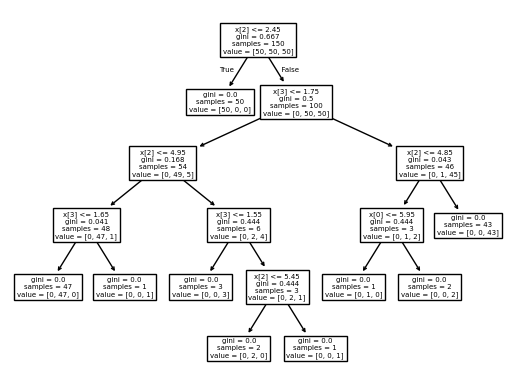

In [ ]:
from sklearn.datasets import load_iris
from sklearn import tree


iris= load_iris()
X = iris.data
y = iris.target
clf = tree.DecisionTreeClassifier()
clf = clf.fit(X, y)
tree.plot_tree(clf)

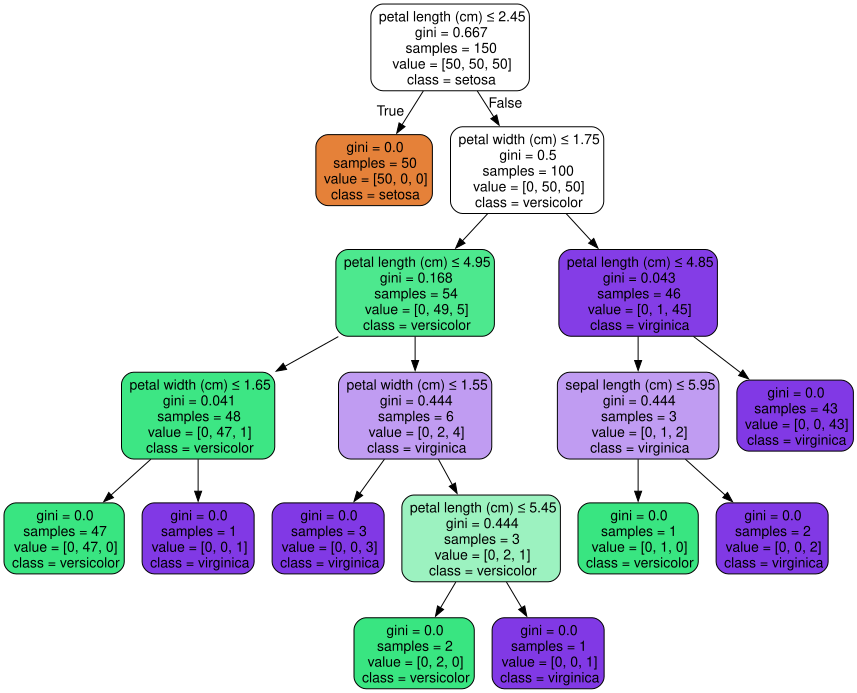

In [ ]:
import graphviz


dot_data = tree.export_graphviz(clf, out_file=None,
                                feature_names=iris.feature_names,
                                class_names=iris.target_names,
                                filled=True, rounded=True,
                                special_characters=True)
graph = graphviz.Source(dot_data)
graph

In [ ]:
from sklearn.tree import export_text


r = export_text(clf, feature_names=iris['feature_names'])
print(r)

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- petal width (cm) <= 1.65
|   |   |   |   |--- class: 1
|   |   |   |--- petal width (cm) >  1.65
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: 2
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- petal length (cm) <= 5.45
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- petal length (cm) >  5.45
|   |   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal length (cm) <= 5.95
|   |   |   |   |--- class: 1
|   |   |   |--- sepal length (cm) >  5.95
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



Чисто используется в медицине***

Может очень сильно поменяться при итерациях

Разделяющая поверхность

C:\Users\nuyki\AppData\Local\Temp\ipykernel_22316\3113487162.py:35: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[idx, 0], X[idx, 1], c=color, label=iris.target_names[i],
C:\Users\nuyki\AppData\Local\Temp\ipykernel_22316\3113487162.py:35: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[idx, 0], X[idx, 1], c=color, label=iris.target_names[i],
C:\Users\nuyki\AppData\Local\Temp\ipykernel_22316\3113487162.py:35: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[idx, 0], X[idx, 1], c=color, label=iris.target_names[i],
C:\Users\nuyki\AppData\Local\Temp\ipykernel_22316\3113487162.py:35: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X[idx, 0], X[idx, 1], c=color, label=iris.target_names[i],
C:\Users\nuyki\AppData\Local\Temp\ipykernel_22316\3113487162.py:35: UserWarn

(np.float64(0.0),
 np.float64(7.88),
 np.float64(-0.9),
 np.float64(3.4800000000000044))

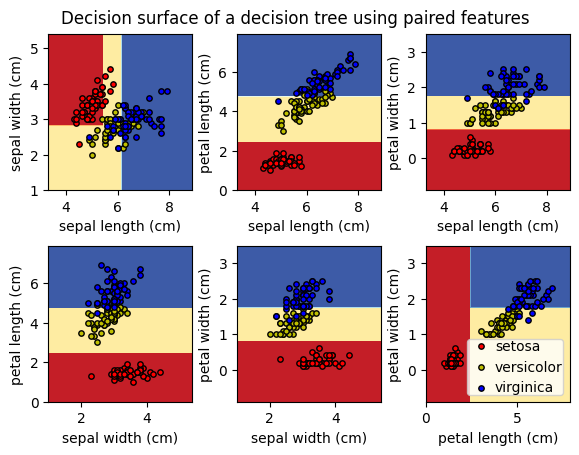

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree


n_classes = 3
plot_colors = 'ryb'
plot_step = .02

iris = load_iris()

for pairidx, pair in enumerate([[0, 1], [0, 2], [0, 3],
                                [1, 2], [1, 3], [2, 3]]):
    X = iris.data[:, pair]
    y = iris.target

    clf = DecisionTreeClassifier(max_depth=2).fit(X, y) #препронинг - обрезание дерева

    plt.subplot(2, 3, pairidx + 1)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    
    plt.tight_layout(h_pad=.5, w_pad=.5, pad=2.5)

    y_pred = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    y_pred = y_pred.reshape(xx.shape)
    cs = plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu)

    plt.xlabel(iris.feature_names[pair[0]])
    plt.ylabel(iris.feature_names[pair[1]])

    for i, color in zip(range(n_classes), plot_colors):
        idx = np.where(y == i)
        plt.scatter(X[idx, 0], X[idx, 1], c=color, label=iris.target_names[i],
                    cmap=plt.cm.RdYlBu, edgecolor='black', s = 15)
        
plt.suptitle('Decision surface of a decision tree using paired features')
plt.legend(loc='lower right', borderpad=0, handletextpad=0)
plt.axis('tight')

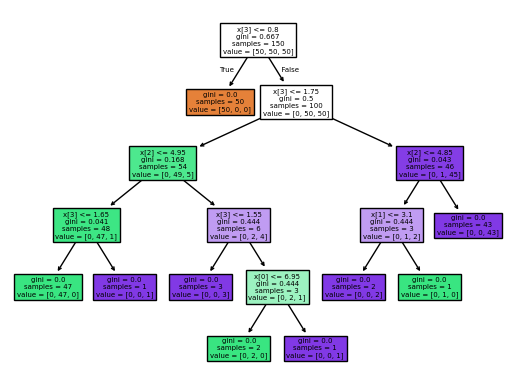

In [ ]:
plt.figure()
clf = DecisionTreeClassifier().fit(iris.data, iris.target)
plot_tree(clf, filled=True)
plt.show()

In [ ]:
clf.feature_importances_ # выводит важность параметров
# Показывает нестабильность деревьев

array([0.01333333, 0.01333333, 0.05072262, 0.92261071])

Дополнительное задание

1. Возьмите датасет на классификацию

2. Обучите модели линейной и логистической регрессий, а также деревья решений

3. Сравните их качество с помощью метрик классификаций (precision, f1,_score, recal, все в sklearn.metrics)